# Q1: Adaptive TCT vs Standard IDP — User Retention and Budget

Compares two Adaptive TCT anytime schedules against Standard IDP composition
across three participation scenarios using RDP accounting (Corollary 2 / Corollary 4):

| Accountant | Schedule | Per-round cost |
|---|---|---|
| Standard IDP (RDP) | — | ρ = αε²/2 every round |
| Adaptive TCT — Zeta-2 | Prop 3 (Zeta-2 δ allocation) | K₁·ρ at registration + Δφ per hit |
| Adaptive TCT — Stitched | Prop 4 (Stitched δ allocation) | K₁·ρ at registration + Δφ per hit |

Non-TCT interleaved rounds charge ρ for all accountants.

**Paper figures (Figure 1):** `figures/h1_rdp_s{1,2,3}_{retention,budget}.png`


In [1]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_dp import StandardDPAccountant
from simulation.accountants.standard_tct import StandardTCTAccountant
from simulation.calibration import q_from_epsilon
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.query import compute_round_conversions, laplace_threshold_query
from simulation.notebook_utils import (
    half_life, pad, hl_label,
    TCT_Z_COLOR, TCT_S_COLOR, IDP_COLOR, PLOT_STYLE,
)

plt.rcParams.update(PLOT_STYLE)

In [2]:
# ── Parameters ────────────────────────────────────────────────────────────────
EPSILON         = 0.01
DELTA           = 1e-2      # δ∞ for both schedules
N_USERS         = 10000
N_ROUNDS        = 1500
EPS_RDP_BUDGET  = 1.0       # per-user ε_RDP budget
TARGET_HIT_RATE = 0.02
ALPHA_POP       = 0.5
BETA_POP        = 2.0
P_PART          = 0.5
INTERLEAVE      = 0.5
SEED            = 42
N_PILOT         = 3000

# ── RDP parameters ────────────────────────────────────────────────────────────
# α=75 gives ρ = αε²/2 = 0.00375; Standard IDP half-life at full participation
# = ε_RDP / ρ = 1.0 / 0.00375 ≈ 267 rounds.
ALPHA_RDP = 75.0
rho = ALPHA_RDP * EPSILON**2 / 2.0   # ρ = αε²/2

q = q_from_epsilon(EPSILON)
pop_cfg = PopulationConfig(
    n_users=N_USERS, alpha=ALPHA_POP, beta=BETA_POP,
    epsilon_budget=EPS_RDP_BUDGET, delta_budget=1.0,
)

print(f'ε={EPSILON},  α={ALPHA_RDP:.0f},  ρ=αε²/2={rho:.6f},  δ∞={DELTA:.0e}')
print(f'q = {q:.4f}  (NotPrior target)')
print(f'ε_RDP budget per user = {EPS_RDP_BUDGET}')
print()

# Key RDP cost landmarks for both schedules
acc_z = AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP, schedule='zeta2')
acc_s = AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP, schedule='stitched')

K1_z  = acc_z.compositions(1);  K1r_z = acc_z.budget_cost(K1_z)
K1_s  = acc_s.compositions(1);  K1r_s = acc_s.budget_cost(K1_s)
print(f'Zeta-2   K₁={K1_z:.1f},  K₁·ρ={K1r_z:.4f}  (registration cost)')
print(f'Stitched K₁={K1_s:.1f},  K₁·ρ={K1r_s:.4f}  (registration cost)')
print()
print('Standard DP RDP exhaustion (half-life theory):')
print(f'  Full participation:       {EPS_RDP_BUDGET/rho:.0f} rounds')
print(f'  Partial (p={P_PART}):     {EPS_RDP_BUDGET/(P_PART*rho):.0f} rounds')


ε=0.01,  α=75,  ρ=αε²/2=0.003750,  δ∞=1e-02
q = 0.4975  (NotPrior target)
ε_RDP budget per user = 1.0

Zeta-2   K₁=24.4,  K₁·ρ=0.0914  (registration cost)
Stitched K₁=84.1,  K₁·ρ=0.3152  (registration cost)

Standard DP RDP exhaustion (half-life theory):
  Full participation:       267 rounds
  Partial (p=0.5):     533 rounds


In [3]:
# ── Threshold calibration ─────────────────────────────────────────────────────
def calibrate_threshold(pop_cfg, p_participate=1.0, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    noisy_counts = np.empty(N_PILOT)
    for i in range(N_PILOT):
        active = pop.active_users
        parts = (list(active) if p_participate >= 1.0
                 else [u for u in active if rng.random() < p_participate])
        if not parts:
            noisy_counts[i] = rng.laplace(0.0, 1.0 / EPSILON)
            continue
        cnt, _ = compute_round_conversions(parts, rng)
        noisy_counts[i] = cnt + rng.laplace(0.0, 1.0 / EPSILON)
    T = float(np.quantile(noisy_counts, 1.0 - TARGET_HIT_RATE))
    return T, float(np.mean(noisy_counts >= T))


# ── Simulation ────────────────────────────────────────────────────────────────
def run_simulation(accountant_factory, pop_cfg, threshold,
                   p_participate=1.0, interleave_ratio=0.0, seed=SEED):
    """RDP simulation: non-TCT rounds charge ρ against each user's ε_RDP budget."""
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    active_frac, avg_budget, hit_rounds = [], [], []

    for r in range(N_ROUNDS):
        active = pop.active_users
        if not active:
            break
        parts = (list(active) if p_participate >= 1.0
                 else [u for u in active if rng.random() < p_participate])
        if parts:
            is_tct = (interleave_ratio == 0.0 or rng.random() >= interleave_ratio)
            if is_tct:
                cnt, contributions = compute_round_conversions(parts, rng)
                is_top, _ = laplace_threshold_query(cnt, threshold, EPSILON, rng)
                if is_top:
                    hit_rounds.append(r)
                for i, user in enumerate(parts):
                    e, d = acc.charge(user=user, is_top=is_top,
                                      contributed=contributions[i], round_num=r)
                    user.epsilon_spent += e
                    user.delta_spent   += d
            else:
                for user in parts:
                    user.epsilon_spent += rho

        pop.drop_depleted()
        eps_dist = pop.epsilon_remaining_distribution()
        active_frac.append(pop.active_fraction)
        avg_budget.append(float(np.mean(eps_dist)) if eps_dist else 0.0)

    return active_frac, avg_budget, hit_rounds


print('Calibrating thresholds...')
T_full,    hr_full    = calibrate_threshold(pop_cfg, p_participate=1.0)
T_partial, hr_partial = calibrate_threshold(pop_cfg, p_participate=P_PART)
print(f'  Full:     T={T_full:.2f},  emp hit rate={hr_full:.3f}')
print(f'  Partial:  T={T_partial:.2f},  emp hit rate={hr_partial:.3f}')


Calibrating thresholds...
  Full:     T=2290.40,  emp hit rate=0.020
  Partial:  T=1295.96,  emp hit rate=0.020


## S1: Full Participation, No Non-TCT Rounds

Standard IDP exhausts at ε_RDP / ρ ≈ **267 rounds**. Both TCT schedules charge
only at registration + hits; Stitched has a larger K₁·ρ upfront but lower per-hit
increments for high-hit users.


In [4]:
print('S1: full participation, no interleaving...')
tct1z_frac, tct1z_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='zeta2', independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=0.0)
tct1s_frac, tct1s_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='stitched', independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=0.0)
idp1_frac, idp1_budget, _ = run_simulation(
    lambda: StandardDPAccountant(rho),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=0.0)

hl_tct1z = half_life(tct1z_frac); hl_tct1s = half_life(tct1s_frac); hl_idp1 = half_life(idp1_frac)
print(f'Zeta-2 hl={hl_tct1z}  Stitched hl={hl_tct1s}  IDP hl={hl_idp1}')


S1: full participation, no interleaving...
Zeta-2 hl=1500  Stitched hl=1500  IDP hl=266


## S2: Full Participation, 50% Non-TCT Rounds

50% of rounds are non-TCT, each charging ρ to all participants. Standard IDP
is unaffected; both TCT schedules accumulate extra ρ charges on non-TCT rounds,
narrowing the advantage.


In [5]:
print('S2: full participation, 50% interleaving...')
tct2z_frac, tct2z_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='zeta2', independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=INTERLEAVE)
tct2s_frac, tct2s_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='stitched', independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=INTERLEAVE)
idp2_frac, idp2_budget, _ = run_simulation(
    lambda: StandardDPAccountant(rho),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=INTERLEAVE)

hl_tct2z = half_life(tct2z_frac); hl_tct2s = half_life(tct2s_frac); hl_idp2 = half_life(idp2_frac)
print(f'Zeta-2 hl={hl_tct2z}  Stitched hl={hl_tct2s}  IDP hl={hl_idp2}')


S2: full participation, 50% interleaving...
Zeta-2 hl=459  Stitched hl=345  IDP hl=266


## S3: 50% Participation, 50% Non-TCT Rounds

Most realistic scenario. Standard IDP exhausts at ε_RDP / (p·ρ) ≈ **533 rounds** (p=0.5).
With partial participation, each user accumulates fewer hits, which favours Zeta-2
(smaller K₁·ρ registration cost) over Stitched.


In [6]:
print('S3: 50% participation, 50% interleaving...')
tct3z_frac, tct3z_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='zeta2', independent=True),
    pop_cfg, T_partial, p_participate=P_PART, interleave_ratio=INTERLEAVE)
tct3s_frac, tct3s_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='stitched', independent=True),
    pop_cfg, T_partial, p_participate=P_PART, interleave_ratio=INTERLEAVE)
idp3_frac, idp3_budget, _ = run_simulation(
    lambda: StandardDPAccountant(rho),
    pop_cfg, T_partial, p_participate=P_PART, interleave_ratio=INTERLEAVE)

hl_tct3z = half_life(tct3z_frac); hl_tct3s = half_life(tct3s_frac); hl_idp3 = half_life(idp3_frac)
print(f'Zeta-2 hl={hl_tct3z}  Stitched hl={hl_tct3s}  IDP hl={hl_idp3}  '
      f'adv-z=+{hl_tct3z-hl_idp3} ({100*(hl_tct3z-hl_idp3)/max(hl_idp3,1):.0f}%)  '
      f'adv-s=+{hl_tct3s-hl_idp3} ({100*(hl_tct3s-hl_idp3)/max(hl_idp3,1):.0f}%)')


S3: 50% participation, 50% interleaving...
Zeta-2 hl=991  Stitched hl=773  IDP hl=532  adv-z=+459 (86%)  adv-s=+241 (45%)


## Section 6: Summary

In [7]:
rows = [
    {'Scenario': 'S1: Full, no interleave',     'p': 1.0,    'intlv': 0.0,
     'Z_hl': hl_tct1z, 'S_hl': hl_tct1s, 'IDP_hl': hl_idp1},
    {'Scenario': 'S2: Full, interleave 50%',     'p': 1.0,    'intlv': INTERLEAVE,
     'Z_hl': hl_tct2z, 'S_hl': hl_tct2s, 'IDP_hl': hl_idp2},
    {'Scenario': 'S3: Partial 50%, intlv 50%',   'p': P_PART, 'intlv': INTERLEAVE,
     'Z_hl': hl_tct3z, 'S_hl': hl_tct3s, 'IDP_hl': hl_idp3},
]
df = pd.DataFrame(rows)
df['Adv-Z'] = df['Z_hl'] - df['IDP_hl']
df['Adv-S'] = df['S_hl'] - df['IDP_hl']
df['Adv-Z%'] = (100 * df['Adv-Z'] / df['IDP_hl'].clip(lower=1)).round(0).astype(int).astype(str) + '%'
df['Adv-S%'] = (100 * df['Adv-S'] / df['IDP_hl'].clip(lower=1)).round(0).astype(int).astype(str) + '%'
print(df[['Scenario', 'p', 'intlv', 'Z_hl', 'S_hl', 'IDP_hl', 'Adv-Z', 'Adv-Z%', 'Adv-S', 'Adv-S%']].to_string(index=False))
print()
print(f'α={ALPHA_RDP:.0f}, ρ={rho:.5f}, ε_RDP budget={EPS_RDP_BUDGET}')
print(f'(ε-DP equivalent: ε={EPSILON}, IDP S1 half-life would be {int(1.0/EPSILON)} rounds)')
print()
print('Note: Stitched schedule has larger K₁·ρ registration cost, so it can be worse')
print(f'      for low-hit-count users. Crossover vs Zeta-2 occurs near k≈150 hits.')

                  Scenario   p  intlv  Z_hl  S_hl  IDP_hl  Adv-Z Adv-Z%  Adv-S Adv-S%
   S1: Full, no interleave 1.0    0.0  1500  1500     266   1234   464%   1234   464%
  S2: Full, interleave 50% 1.0    0.5   459   345     266    193    73%     79    30%
S3: Partial 50%, intlv 50% 0.5    0.5   991   773     532    459    86%    241    45%

α=75, ρ=0.00375, ε_RDP budget=1.0
(ε-DP equivalent: ε=0.01, IDP S1 half-life would be 100 rounds)

Note: Stitched schedule has larger K₁·ρ registration cost, so it can be worse
      for low-hit-count users. Crossover vs Zeta-2 occurs near k≈150 hits.


## Paper Figures — Individual S1 / S2 / S3 Panels

One retention figure and one budget figure per scenario.


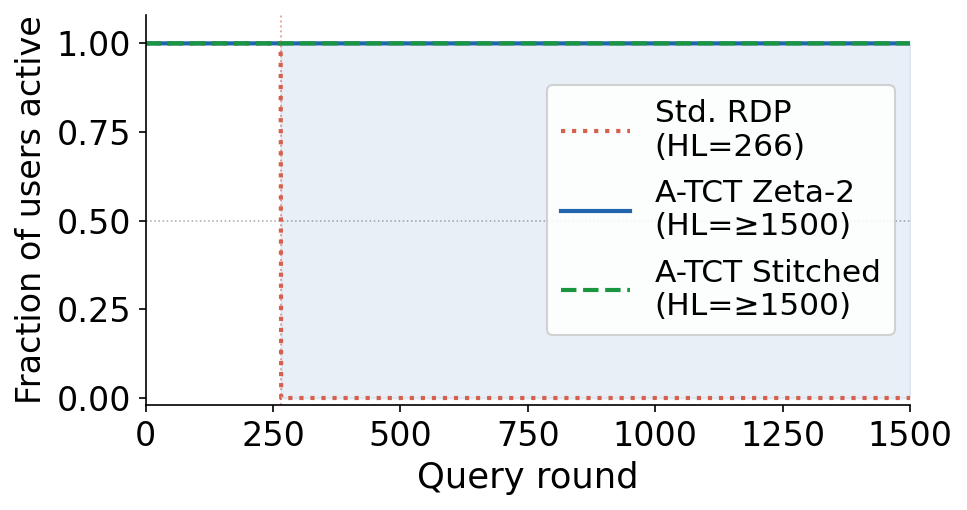

Saved ../figures/h1_rdp_s1_retention.png


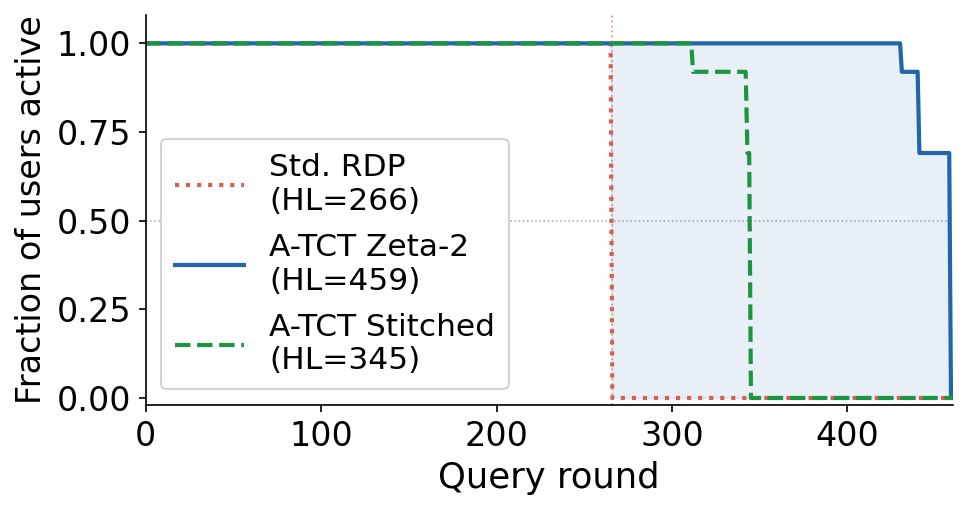

Saved ../figures/h1_rdp_s2_retention.png


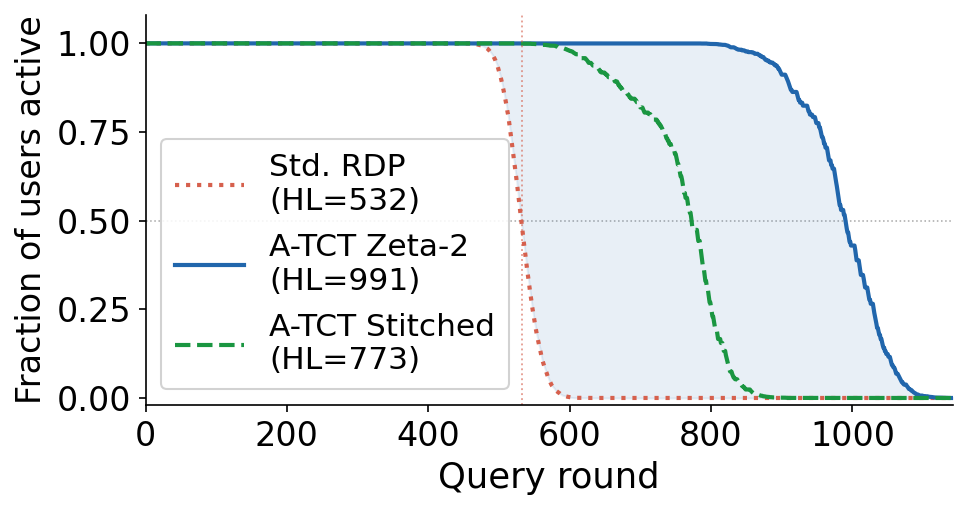

Saved ../figures/h1_rdp_s3_retention.png


In [8]:
# ── Individual S1 / S2 / S3: User Retention ─────────────────────────────────
retention_panels = [
    (tct1z_frac, tct1s_frac, idp1_frac, hl_tct1z, hl_tct1s, hl_idp1,
     'center right', '../figures/h1_rdp_s1_retention.png'),
    (tct2z_frac, tct2s_frac, idp2_frac, hl_tct2z, hl_tct2s, hl_idp2,
     'lower left',   '../figures/h1_rdp_s2_retention.png'),
    (tct3z_frac, tct3s_frac, idp3_frac, hl_tct3z, hl_tct3s, hl_idp3,
     'lower left',   '../figures/h1_rdp_s3_retention.png'),
]
for zf, sf, idpf, hl_z, hl_s, hl_i, leg_loc, fname in retention_panels:
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    n = max(len(zf), len(sf), len(idpf)) + 1
    rnds = list(range(n))
    za = pad(zf, n); sa = pad(sf, n); ia = pad(idpf, n)
    ax.plot(rnds, ia, color=IDP_COLOR,   lw=2.0, linestyle=':', label=f'Std. RDP\n(HL={hl_i})')
    ax.plot(rnds, za, color=TCT_Z_COLOR, lw=2.0,
            label=f'A-TCT Zeta-2\n(HL={hl_label(hl_z, n)})')
    ax.plot(rnds, sa, color=TCT_S_COLOR, lw=2.0, linestyle='--',
            label=f'A-TCT Stitched\n(HL={hl_label(hl_s, n)})')
    ax.fill_between(rnds, ia, za, alpha=0.10, color=TCT_Z_COLOR)
    ax.axhline(0.5, color='#aaa', lw=0.75, linestyle=':', zorder=0)
    if hl_i < n - 2:
        ax.axvline(hl_i, color=IDP_COLOR, lw=0.9, linestyle=':', alpha=0.6)
    ax.set_xlabel('Query round', fontsize=17)
    ax.set_ylabel('Fraction of users active', fontsize=16)
    ax.set_xlim(0, n - 1); ax.set_ylim(-0.02, 1.08)
    ax.tick_params(axis='both', which='major', labelsize=16)
    ax.legend(loc=leg_loc, fontsize=15, frameon=True, framealpha=0.88,
              borderpad=0.45, labelspacing=0.55, handlelength=2.2)
    plt.tight_layout()
    fig.subplots_adjust(top=0.97)
    plt.savefig(fname, bbox_inches='tight', dpi=200)
    plt.show()
    print(f'Saved {fname}')


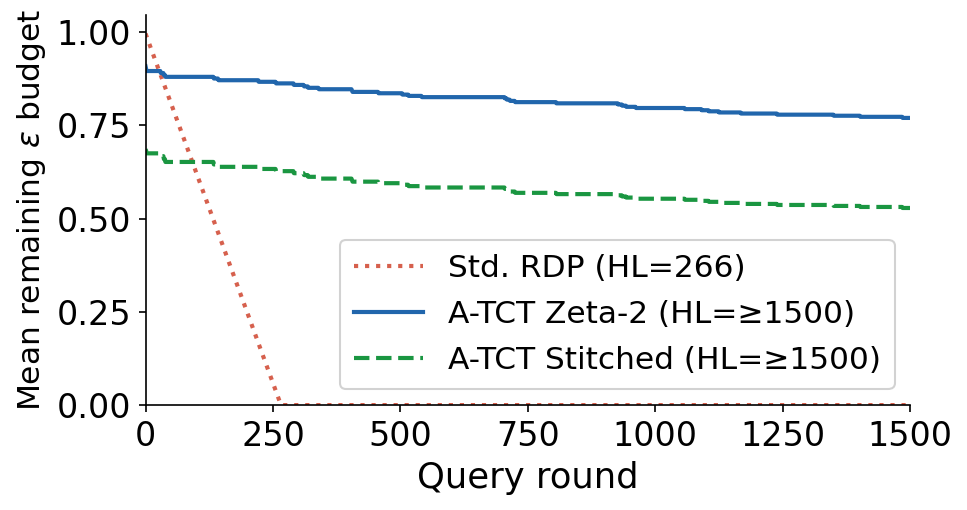

Saved ../figures/h1_rdp_s1_budget.png


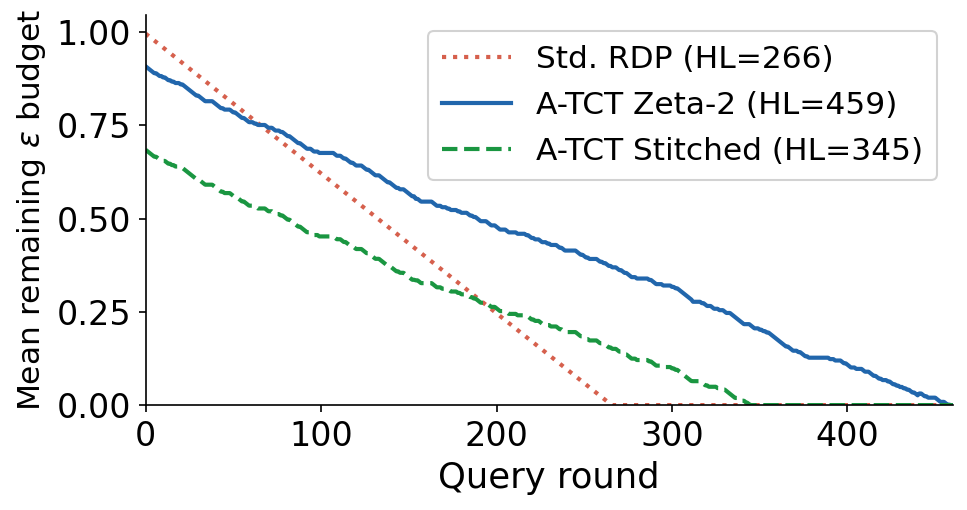

Saved ../figures/h1_rdp_s2_budget.png


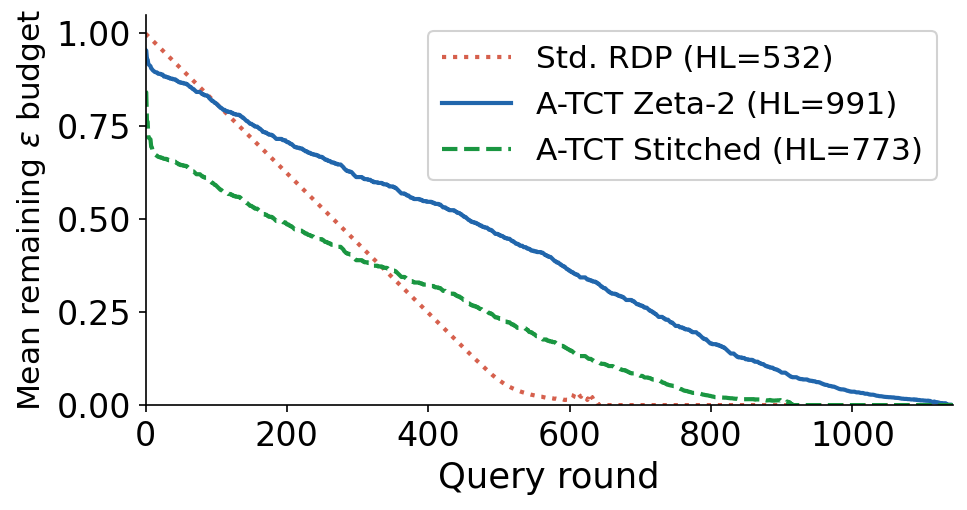

Saved ../figures/h1_rdp_s3_budget.png


In [9]:
# ── Individual S1 / S2 / S3: Budget Degradation ─────────────────────────────
budget_panels = [
    (tct1z_budget, tct1s_budget, idp1_budget, hl_tct1z, hl_tct1s, hl_idp1,
     'lower right', '../figures/h1_rdp_s1_budget.png'),
    (tct2z_budget, tct2s_budget, idp2_budget, hl_tct2z, hl_tct2s, hl_idp2,
     'upper right', '../figures/h1_rdp_s2_budget.png'),
    (tct3z_budget, tct3s_budget, idp3_budget, hl_tct3z, hl_tct3s, hl_idp3,
     'upper right', '../figures/h1_rdp_s3_budget.png'),
]
for zb, sb, ib, hl_z, hl_s, hl_i, leg_loc, fname in budget_panels:
    fig, ax = plt.subplots(figsize=(6.5, 3.5))
    n = max(len(zb), len(sb), len(ib)) + 1
    rnds = list(range(n))
    zb_ = pad(zb, n); sb_ = pad(sb, n); ib_ = pad(ib, n)
    ax.plot(rnds, ib_, color=IDP_COLOR,   lw=2.0, linestyle=':', label=f'Std. RDP (HL={hl_i})')
    ax.plot(rnds, zb_, color=TCT_Z_COLOR, lw=2.0,               label=f'A-TCT Zeta-2 (HL={hl_label(hl_z, n)})')
    ax.plot(rnds, sb_, color=TCT_S_COLOR, lw=2.0, linestyle='--', label=f'A-TCT Stitched (HL={hl_label(hl_s, n)})')
    ax.axhline(0, color='#888', lw=0.5, zorder=0)
    ax.set_xlabel('Query round', fontsize=17)
    ax.set_ylabel(r'Mean remaining $\varepsilon$ budget', fontsize=15)
    ax.set_xlim(0, n - 1); ax.set_ylim(bottom=0)
    ax.tick_params(axis='both', which='major', labelsize=16)
    ax.legend(loc=leg_loc, fontsize=15, frameon=True, framealpha=0.88,
              borderpad=0.45, labelspacing=0.55, handlelength=2.2)
    plt.tight_layout()
    fig.subplots_adjust(top=0.97)
    plt.savefig(fname, bbox_inches='tight', dpi=200)
    plt.show()
    print(f'Saved {fname}')
